In [5]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import joblib

In [6]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
if not os.path.exists("AirPassengers.csv"):
    urllib.request.urlretrieve(url, "AirPassengers.csv")

df = pd.read_csv("AirPassengers.csv")

if 'Passengers' in df.columns:
    df.rename(columns={'Passengers': '#Passengers'}, inplace=True)

df['Month'] = pd.to_datetime(df['Month'])
df.set_index('Month', inplace=True)

In [7]:
# 2. PREPROCESSING & WINDOWING DATA
passengers_data = df['#Passengers'].values.reshape(-1, 1)

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(passengers_data)

timesteps = 12
X, y = [], []

for i in range(timesteps, len(scaled_data)):
    X.append(scaled_data[i-timesteps:i, 0])
    y.append(scaled_data[i, 0])

X, y = np.array(X), np.array(y)
X = np.reshape(X, (X.shape[0], X.shape[1], 1))

train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

In [8]:
# 3. BUILD & TRAIN MODEL LSTM
model = Sequential([
    LSTM(units=50, return_sequences=True, input_shape=(X.shape[1], 1)),
    Dropout(0.2),
    LSTM(units=50, return_sequences=False),
    Dropout(0.2),
    Dense(units=25),
    Dense(units=1)
])

model.compile(optimizer='adam', loss='mean_squared_error')

print("--- Memulai Training Model ---")
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

--- Memulai Training Model ---
Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step - loss: 0.0638 - val_loss: 0.0438
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0215 - val_loss: 0.0215
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0132 - val_loss: 0.0580
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0142 - val_loss: 0.0399
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0092 - val_loss: 0.0218
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0091 - val_loss: 0.0231
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0099 - val_loss: 0.0236
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0086 - val_loss: 0.0256
Epoch 9/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0092 - val_loss: 0.0234
Epoch 10/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0087 - val_loss: 0.0227
Epoch 11/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0090 - val_loss: 0.0216
Epoch 12/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0078 - val_loss: 0.0218
Epoch 13/50

In [9]:
# 4. PREDIKSI & EVALUASI (RMSE)
predictions = model.predict(X_test)
predictions_actual = scaler.inverse_transform(predictions)
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

mse = mean_squared_error(y_test_actual, predictions_actual)
rmse = np.sqrt(mse)
print(f"\nNilai Root Mean Squared Error (RMSE): {rmse:.2f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   

Nilai Root Mean Squared Error (RMSE): 71.35


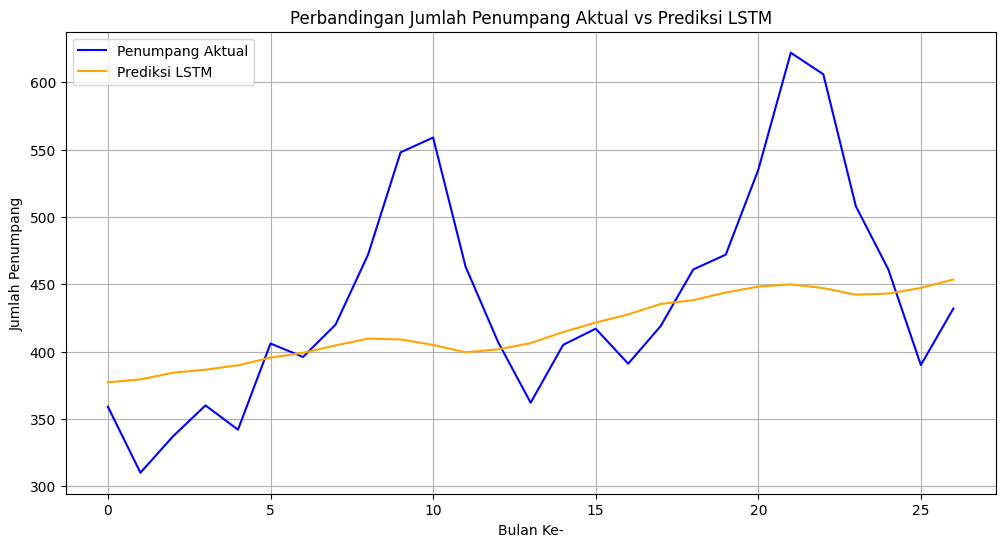

In [10]:
# 5. VISUALISASI HASIL PREDIKSI
plt.figure(figsize=(12, 6))
plt.plot(y_test_actual, color='blue', label='Penumpang Aktual')
plt.plot(predictions_actual, color='orange', label='Prediksi LSTM')
plt.title('Perbandingan Jumlah Penumpang Aktual vs Prediksi LSTM')
plt.xlabel('Bulan Ke-')
plt.ylabel('Jumlah Penumpang')
plt.legend()
plt.grid(True)
plt.show()

In [11]:
# 6. SIMPAN MODEL & SCALER UNTUK FLASK
model.save("model_lstm_passengers.h5")
joblib.dump(scaler, "scaler.pkl")
print("\nModel (.h5) dan Scaler (.pkl) berhasil disimpan!")


Model (.h5) dan Scaler (.pkl) berhasil disimpan!
